<a href="https://colab.research.google.com/github/fforster/alerce-iucaa-2026/blob/main/02_one_source_two_surveys.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · One source, two surveys

**ALeRCE multisurvey tutorial — IUCAA 2026** · ~25 min

We follow three sources in the COSMOS field that were observed by **both ZTF and LSST**:

| ZTF name | What it is |
|---|---|
| `ZTF26aaonmha` | SN 2026gzf, a type Ic-BL supernova |
| `ZTF20acyxpwi` | a quasar |
| `ZTF17aabhbva` | an RR Lyrae star |

You will learn to
1. find the LSST counterpart(s) of a ZTF object (and vice versa);
2. use the **multisurvey REST API** endpoint by endpoint;
3. compare light curves, classifications and image stamps from the two surveys;
4. use the **experimental explorer** for crossmatches and spectroscopic redshifts.

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip -q install pyvo astroquery
    !wget -q -N https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/alerce_ms.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import alerce_ms as am

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 1. Finding counterparts across surveys

Remember **rule 2** from notebook 01: there is no cross-survey object association. The link between a ZTF object
and an LSST object is purely **positional**. The light-curve API has a cone search that looks in *all* surveys at
once (`lightcurve_api/conesearch/objects_by_coordinates`; its radius is in degrees). `am.find_counterparts` wraps it.

First we need the position of each ZTF object, from `object_api/object`:

In [2]:
names = {"ZTF26aaonmha": "SN Ic-BL", "ZTF20acyxpwi": "quasar", "ZTF17aabhbva": "RR Lyrae"}

ztf_objects = pd.DataFrame([am.get_object(name, "ztf") for name in names])
ztf_objects.insert(0, "name", list(names))
ztf_objects.insert(1, "type", list(names.values()))
ztf_objects[["name", "type", "oid", "meanra", "meandec", "firstmjd", "lastmjd", "n_det", "n_forced", "n_non_det"]]

,name,type,oid,meanra,meandec,firstmjd,lastmjd,n_det,n_forced,n_non_det
0,ZTF26aaonmha,SN Ic-BL,36029005852662990,149.928671,0.418448,61121.316262,61185.211435,39,36,54
1,ZTF20acyxpwi,quasar,36028957690312632,150.700525,3.532180,60052.232188,60818.178958,92,128,489
2,ZTF17aabhbva,RR Lyrae,36028933560318190,150.170670,1.368242,58464.467164,61332.531343,573,247,685


In [3]:
matches = []
for row in ztf_objects.itertuples():
    c = am.find_counterparts(row.meanra, row.meandec, radius_arcsec=2.0)
    c.insert(0, "ztf_name", row.name)
    matches.append(c)
matches = pd.concat(matches, ignore_index=True)
matches[["ztf_name", "name", "survey", "sid", "oid", "sep_arcsec"]]

,ztf_name,name,survey,sid,oid,sep_arcsec
0,ZTF26aaonmha,ZTF26aaonmha,ztf,0,36029005852662990,0.000000
1,ZTF26aaonmha,314003014107006318,lsst,1,314003014107006318,0.125596
2,ZTF20acyxpwi,ZTF20acyxpwi,ztf,0,36028957690312632,0.000000
3,ZTF20acyxpwi,313985345706262538,lsst,1,313985345706262538,0.439534
4,ZTF17aabhbva,ZTF17aabhbva,ztf,0,36028933560318190,0.000000
5,ZTF17aabhbva,313893021775560722,lsst,1,313893021775560722,0.041680
6,ZTF17aabhbva,313888627082919999,lsst,1,313888627082919999,0.042963


* The supernova and the quasar each have **one** LSST counterpart within 0.5″.
* The RR Lyrae star has **two** LSST diaObjects. Let us look at them:

In [4]:
rrl_lsst = matches.query("ztf_name == 'ZTF17aabhbva' and survey == 'lsst'").oid.tolist()
pd.DataFrame([am.get_object(oid, "lsst") for oid in rrl_lsst])[
    ["oid", "meanra", "meandec", "firstmjd", "lastmjd", "n_det", "n_forced"]]

,oid,meanra,meandec,firstmjd,lastmjd,n_det,n_forced
0,313893021775560722,150.170671,1.36823,61032.328003,61205.988991,723,1191
1,313888627082919999,150.170671,1.36823,61032.328003,61099.317816,553,970


Both objects are at the same position (≈0.04″ from the ZTF position) and their time ranges overlap. Rubin's
alert-production association sometimes splits one star into several diaObjects (for example after
reprocessing, or when sources are de-blended differently). **When you combine LSST data for a star, check for
duplicate diaObjects and merge them.** We do exactly that in notebook 05.

The same cone search can be done with ADQL on the `object` table (`am.tap_cone`), useful when you want extra
columns or many positions:

In [5]:
sn = ztf_objects.iloc[0]
am.tap_cone(sn.meanra, sn.meandec, radius_arcsec=2.0).pipe(am.decode)

,oid,sid,meanra,meandec,firstmjd,lastmjd,n_det,n_forced,sep_arcsec,survey_name
0,36029005852662990,0,149.928671,0.418448,61121.316262,61185.211435,39,36,0.000000,ZTF
1,314003014107006318,1,149.928639,0.418435,61058.299537,61204.981752,108,152,0.125596,LSST DIA Object


Let us store the pairs we will use:

In [6]:
pairs = {
    "ZTF26aaonmha": [314003014107006318],
    "ZTF20acyxpwi": [313985345706262538],
    "ZTF17aabhbva": rrl_lsst,
}

## 2. The multisurvey REST API, endpoint by endpoint

Each service lives at `https://api-lsst.alerce.online/<name>_api/<endpoint>` and documents itself at
`.../<name>_api/docs`. `am.api_get(service, endpoint, **params)` is a three-line wrapper around `requests.get`.

### 2.1 `object_api`

Besides `/object` (used above), `/list_objects` filters by classifier, class, probability, dates and position —
the same query that powers the explorers. Here: LSST objects classified as AGN within 1° of COSMOS.
(Radius in arcsec here. Note: the `total` field of the answer is not reliable at the moment; use paging.)

In [7]:
res = am.api_get("object", "list_objects", survey="lsst", classifier="stamp_classifier_rubin_beta_20260421",
                 class_name="AGN", probability=0.5, ra=150.1, dec=2.2, radius=3600, page_size=5)
pd.DataFrame(res["items"])[["oid", "meanra", "meandec", "n_det", "class_name", "probability"]]

,oid,meanra,meandec,n_det,class_name,probability
0,170028500609138838,150.599724,2.398199,741,AGN,0.971371
1,170028510512414824,149.563710,1.794029,410,AGN,0.970841
2,170046092236816512,150.158973,2.825085,40,AGN,0.970648
3,170028510544396398,150.732899,1.625106,377,AGN,0.970623
4,170028510496161953,150.137793,3.072841,278,AGN,0.970420


### 2.2 `lightcurve_api`

`/lightcurve` returns detections, non-detections and forced photometry in one call. Each detection carries the full
native record of its survey: for LSST, Rubin's DiaSource columns (`psfFlux`, `scienceFlux`, `reliability`, …).

In [8]:
lc_json = am.api_get("lightcurve", "lightcurve", oid=314003014107006318, survey_id="lsst")
print({k: len(v) for k, v in lc_json.items()})
pd.DataFrame(lc_json["detections"]).iloc[:3, :14]

{'detections': 108, 'non_detections': 0, 'forced_photometry': 10}


,band_map,band,mjd,survey_id,ra,dec,oid,measurement_id,parentDiaSourceId,diaObjectId,psfFlux,psfFluxErr,psfFlux_flag,psfFlux_flag_edge
0,"{'6': 'u', '1': 'g', '2': 'r', '3': 'i', '4': ...",1,61090.188512,lsst,149.928674,0.418430,314003014107006318,170028512361055259,0,314003014107006318,-822.8331,222.72534,0,0
1,"{'6': 'u', '1': 'g', '2': 'r', '3': 'i', '4': ...",1,61090.189604,lsst,149.928846,0.418383,314003014107006318,170028512675102994,0,314003014107006318,1853.3467,202.62961,0,0
2,"{'6': 'u', '1': 'g', '2': 'r', '3': 'i', '4': ...",1,61090.190066,lsst,149.928676,0.418431,314003014107006318,170028512810893390,0,314003014107006318,313.9914,229.10454,0,0


For ZTF use the **integer** `oid` with `/detections` and `/non_detections`. (At the time of writing, the ZTF
`/lightcurve` and `/forced-photometry` endpoints fail; get ZTF forced photometry from TAP with
`am.get_lightcurve`.)

In [9]:
sn_oid = am.ztf_name_to_oid("ZTF26aaonmha")
ztf_det = pd.DataFrame(am.api_get("lightcurve", "detections", oid=sn_oid, survey_id="ztf"))
ztf_det[["mjd", "band", "magpsf", "sigmapsf", "isdiffpos", "rb", "drb", "has_stamp"]].head()

,mjd,band,magpsf,sigmapsf,isdiffpos,rb,drb,has_stamp
0,61185.211435,3,18.769842,0.162737,1,0.714286,0.943413,True
1,61170.185139,2,18.366873,0.073445,1,0.952857,1.000000,True
2,61168.193854,1,19.435547,0.158248,1,0.964286,0.999994,True
3,61168.171852,2,18.279016,0.089864,1,0.928571,0.999999,True
4,61167.255521,1,19.354097,0.162556,1,0.970000,0.999996,True


### 2.3 `probability_api`, `magstat_api`, `crossmatch_api`, `classifier_api`

In [10]:
pd.DataFrame(am.api_get("probability", "probability", oid=314003014107006318)).sort_values(
    ["classifier_name", "ranking"]).head(10)

,classifier_name,classifier_version,class_name,probability,ranking
9,stamp_classifier_rubin_beta,201,bogus,0.589957,1
3,stamp_classifier_rubin_beta,201,AGN,0.283899,2
4,stamp_classifier_rubin_beta,201,VS,0.122019,3
0,stamp_classifier_rubin_beta,201,SN,0.002871,4
7,stamp_classifier_rubin_beta,201,asteroid,0.001254,5
8,stamp_classifier_rubin_beta_20260421,202,bogus,0.465457,1
2,stamp_classifier_rubin_beta_20260421,202,AGN,0.457080,2
1,stamp_classifier_rubin_beta_20260421,202,SN,0.050061,3
5,stamp_classifier_rubin_beta_20260421,202,VS,0.026091,4
6,stamp_classifier_rubin_beta_20260421,202,asteroid,0.001311,5


⚠️ The API is not yet consistent about ZTF identifiers: the `lightcurve_api` and `probability_api` endpoints want
the integer `oid`, while `magstat_api` and `crossmatch_api` want the ZTF name (`object_api` accepts both).
If one form fails (HTTP 400/500), try the other.

In [11]:
pd.DataFrame(am.api_get("magstat", "magstats", oid="ZTF26aaonmha", survey_id="ztf"))[
    ["ndet", "magmean", "magmin", "magmax", "magfirst", "maglast", "firstmjd", "lastmjd"]]

,ndet,magmean,magmin,magmax,magfirst,maglast,firstmjd,lastmjd
0,13,18.618,17.380,19.699,19.699,19.436,61121.316,61168.194
1,15,17.601,16.978,18.367,17.615,18.367,61125.211,61170.185
2,11,17.738,17.177,18.770,17.840,18.770,61125.269,61185.211


`crossmatch_api` returns the nearest source in each of the catalogs of the ALeRCE **catsHTM** service (2MASS, WISE,
GALEX, XMM, SDSS spectra, NED redshifts, Gaia, …). We use it heavily for the quasar in notebook 04:

In [12]:
xm = am.api_get("crossmatch", "crossmatch", oid="ZTF20acyxpwi", survey_id="ztf")
{list(item)[0]: round(list(item.values())[0]["distance"]["value"], 2) for item in xm}   # catalog: distance ["]

{'2MASS': 0.38,
 'DECaLS': 0.43,
 'GAIA/DR1': 0.44,
 'GAIA/DR2': 0.44,
 'GALEX': 0.47,
 'NEDz': 0.47,
 'SDSS/DR10': 0.47,
 'SDSSoffset': 0.47,
 'SpecSDSS': 0.47,
 'UKIDSS': 0.47,
 'PTFpc': 0.5,
 'WISE': 0.48,
 'XMM': 0.03,
 'unWISE': 0.45}

### 2.4 API or TAP?

| | API | TAP |
|---|---|---|
| one object, everything about it | ✅ simple JSON | ✅ several queries |
| many objects / samples | one request per object 😬 | ✅ one query |
| arbitrary joins, features, catalog columns | ❌ | ✅ |
| ZTF forced photometry, features | ❌ (for now) | ✅ |

`am.get_lightcurve(oid, sid)` uses TAP and returns the same columns for both surveys. Let us use it from now on.

## 3. Light curves from both surveys

For each pair we download the ZTF and LSST light curves (detections + forced photometry):

In [13]:
lcs = {}
for ztf_name, lsst_oids in pairs.items():
    parts = [am.get_lightcurve(ztf_name, 0)] + [am.get_lightcurve(oid, 1) for oid in lsst_oids]
    lcs[ztf_name] = pd.concat(parts, ignore_index=True)
    print(ztf_name, lcs[ztf_name].groupby("survey").size().to_dict())

ZTF26aaonmha {'lsst': 260, 'ztf': 75}


ZTF20acyxpwi {'lsst': 1851, 'ztf': 220}


ZTF17aabhbva {'lsst': 3437, 'ztf': 820}


Which quantity should we plot?
* **Supernova:** the *difference* flux — the host galaxy is removed by the subtraction.
* **Quasar and RR Lyrae:** the *total* brightness (`sci_mag`): the template already contains the source at some
  average brightness, so the difference flux would oscillate around zero.

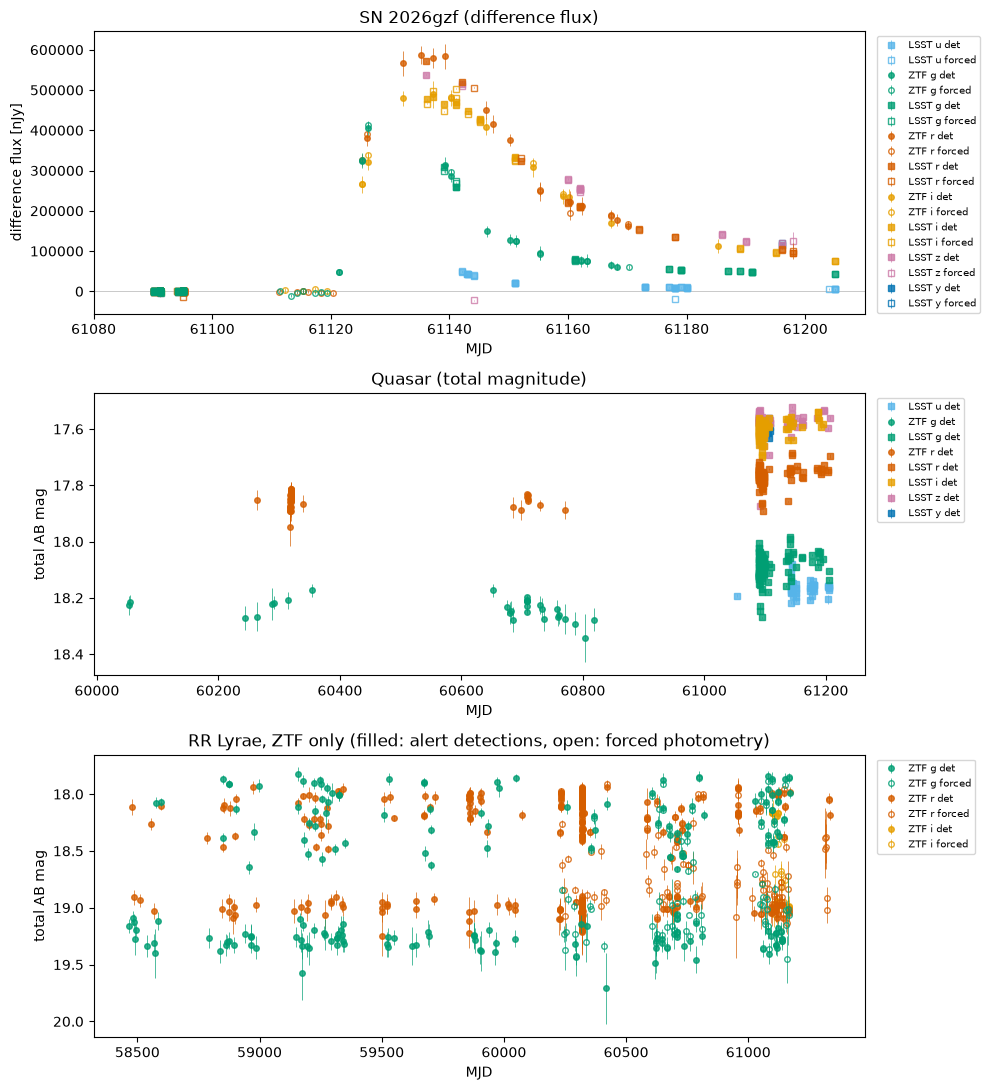

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(10, 11))
am.plot_lightcurve(lcs["ZTF26aaonmha"], flux="diff", ax=axes[0], title="SN 2026gzf (difference flux)")
axes[0].set_xlim(61080, 61210)
am.plot_lightcurve(lcs["ZTF20acyxpwi"], flux="sci", mag=True, ax=axes[1], title="Quasar (total magnitude)",
                   show_forced=False)
rrl_ztf = lcs["ZTF17aabhbva"].query("survey == 'ztf'")
am.plot_lightcurve(rrl_ztf, flux="sci", mag=True, ax=axes[2],
                   title="RR Lyrae, ZTF only (filled: alert detections, open: forced photometry)")
plt.tight_layout()

Look at the RR Lyrae panel: the ZTF **alert detections** (filled) pile up at two levels, ~0.5 mag above and below
the mean, with a gap in between, while the **forced photometry** (open; available for this star since ~MJD 60250)
also lands inside the gap. Why? An alert is only
issued when the source differs from the *template* by ≥ 5σ. The template shows the star at its average brightness,
so epochs near the average never produce alerts. **Alert light curves of variable stars are biased; use forced
photometry when you can.**

Things to notice:
* ZTF has a **long baseline** (since 2018) but only g, r, i; LSST adds u, z, y, many more points per night
  (COSMOS is a deep drilling field) and much better photometric precision.
* The quasar shows slow, stochastic variability over years, the RR Lyrae star a large-amplitude scatter that will
  become a clean curve once we fold it with the right period (notebook 05).
* ZTF `magpsf_corr`/`mag_corr` (apparent magnitudes) and LSST `scienceFlux` are measured differently (reference
  flux added back vs. flux on the direct image), and the filters differ: small offsets between surveys are normal.

## 4. Classifications in the two surveys

ZTF objects are classified by the light-curve classifier (full history) and the ZTF stamp classifier (first alert);
LSST objects, for now, by the Rubin stamp classifiers. Let us compare the top class of each:

In [15]:
rows = []
for ztf_name, lsst_oids in pairs.items():
    for sid, oid in [(0, ztf_name)] + [(1, o) for o in lsst_oids]:
        p = am.get_probabilities(oid, sid).query("ranking == 1")
        for r in p.itertuples():
            rows.append(dict(source=names[ztf_name], survey=am.SURVEY[sid], oid=am.as_oid(oid),
                             classifier=r.classifier_name, top_class=r.class_name,
                             probability=round(r.probability, 3)))
pd.DataFrame(rows)

,source,survey,oid,classifier,top_class,probability
0,SN Ic-BL,ztf,36029005852662990,lc_classifier_BHRF_forced_phot,SESN,0.426
1,SN Ic-BL,ztf,36029005852662990,lc_classifier_BHRF_forced_phot_periodic,RRLab,0.364
2,SN Ic-BL,ztf,36029005852662990,lc_classifier_BHRF_forced_phot_stochastic,CV/Nova,0.648
3,SN Ic-BL,ztf,36029005852662990,lc_classifier_BHRF_forced_phot_top,Transient,0.952
4,SN Ic-BL,ztf,36029005852662990,lc_classifier_BHRF_forced_phot_transient,SESN,0.448
5,SN Ic-BL,ztf,36029005852662990,stamp_classifier,bogus,0.421
6,SN Ic-BL,ztf,36029005852662990,stamp_classifier_2025_beta,bogus,0.548
7,SN Ic-BL,lsst,314003014107006318,stamp_classifier_rubin_beta,bogus,0.590
8,SN Ic-BL,lsst,314003014107006318,stamp_classifier_rubin_beta_20260421,bogus,0.465
9,quasar,ztf,36028957690312632,lc_classifier_BHRF_forced_phot,QSO,0.831


* The ZTF light-curve classifier gets all three right: **Transient → SESN**, **Stochastic → QSO**, **Periodic → RRLab**.
* The stamp classifiers only see the image triplet of the **first** alert. For the supernova, ZTF's first alert was
  called *bogus*, and so was LSST's — whose first detection was a weak residual on the host galaxy, weeks before
  the explosion (see notebook 01). For the quasar, the ZTF stamp classifier says AGN, while the Rubin (beta)
  stamp classifiers say VS (variable star): from a single stamp a point-like variable quasar looks like a star.
* Lessons: **a classification depends on the data the model saw** (`lastmjd`); stamp classes are a fast first
  guess, light-curve classes are more reliable; and combining surveys gives you more information than either alone.

## 5. Image stamps

Every alert carries three small images: the **science** image, the **template** (reference) and their
**difference**. Let us compare ZTF and LSST stamps of the supernova near maximum light.

ZTF  peak detection: MJD 61135.17, band r
LSST peak detection: MJD 61136.02, band r


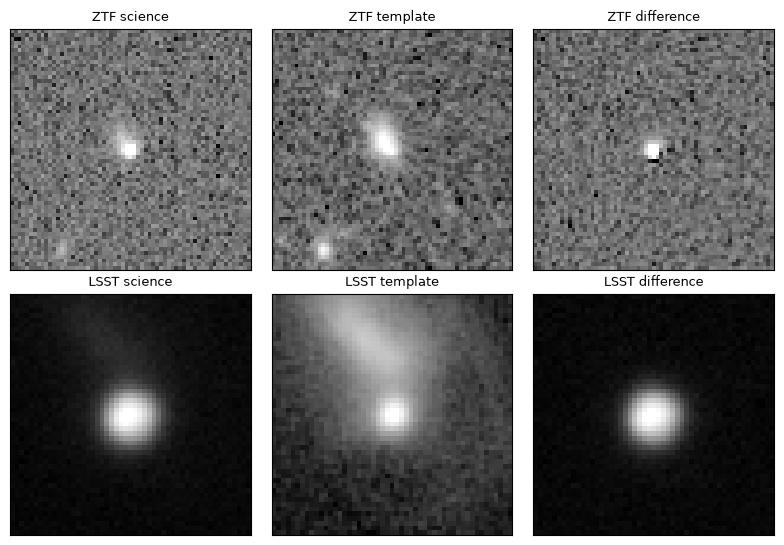

In [16]:
lc = lcs["ZTF26aaonmha"]
ztf_peak = lc.query("survey == 'ztf' and kind == 'det'").sort_values("diff_flux").iloc[-1]
lsst_dets = pd.DataFrame(lc_json["detections"]).query("has_stamp")
lsst_peak = lsst_dets.sort_values("psfFlux").iloc[-1]
print(f"ZTF  peak detection: MJD {ztf_peak.mjd:.2f}, band {ztf_peak.band_name}")
print(f"LSST peak detection: MJD {lsst_peak.mjd:.2f}, band {lsst_peak.band_map[str(lsst_peak.band)]}")

fig, axes = plt.subplots(2, 3, figsize=(8, 5.5))
am.plot_stamps(am.get_stamps(sn_oid, 0, int(ztf_peak.measurement_id)), "ZTF", axes[0])
am.plot_stamps(am.get_stamps(314003014107006318, 1, int(lsst_peak.measurement_id)), "LSST", axes[1])
plt.tight_layout()

ZTF stamps are 63×63 pixels of 1.0″ (≈1′ across); LSST stamps are 51×51 pixels of 0.2″ (≈10″ across). With LSST we
see the structure of the host galaxy and the supernova on top of it.

## 6. The experimental explorer

The experimental explorer (ALeRCE Labs) shows ZTF and LSST data together, plus ZTF data-release light curves,
crossmatches with many catalogs and spectroscopic redshifts. It also exposes a small JSON API. `am.explorer_xmatch`
returns what the explorer overlays on the sky around an object:

In [17]:
for ztf_name in pairs:
    am.show_link(ztf_name, "ztf", f"{ztf_name} ({names[ztf_name]}) in the experimental explorer")

In [18]:
am.explorer_xmatch("ZTF26aaonmha", "ztf").head(10)

,cat_name,category,name,type,z,z_err,sep,ra,dec
0,VSX,stellar,SN 2026gzf,SN Ic-BL,NaN,NaN,0.030312,149.928670,0.418440
1,Gaia DR3,stellar,3833530685621513728,star,NaN,NaN,0.086096,149.928687,0.418430
2,Simbad,stellar,SN 2026gzf,Supernova,0.034300,NaN,0.140769,149.928633,0.418439
3,NED,host,SDSS J095942.88+002506.2,G,0.034514,0.000297,0.178264,149.928667,0.418399
4,Simbad,host,2dFGRS TGN352Z077,Galaxy,0.034500,NaN,0.199212,149.928670,0.418393
5,Simbad,stellar,AT 2018mtl,Transient,NaN,NaN,0.343035,149.928708,0.418536
6,2dFGRS,host,2dFGRS J095942.9+002503.9,NaN,0.034500,NaN,2.613759,149.928870,0.417750
7,HECATE,host,PGC1165398,NaN,0.034510,0.000166,3.337126,149.928900,0.417550
8,GLADE v2,host,GLADE v2 J095943.0+002503.2,G,0.034407,NaN,3.443662,149.929000,0.417550
9,DESI,host,DESI J149.9299+00.4181,GALAXY,0.034328,0.000006,4.680830,149.929947,0.418195


For the supernova the explorer finds the TNS name (SN 2026gzf, type Ic-BL in VSX/TNS) and, in the `host`
category, its host galaxy with spectroscopic redshift z ≈ 0.0345 from NED, 2dFGRS, HECATE, GLADE and DESI.
Notebook 03 uses this, together with the DELIGHT host finder.

In [19]:
for ztf_name in ["ZTF20acyxpwi", "ZTF17aabhbva"]:
    x = am.explorer_xmatch(ztf_name, "ztf")
    print(ztf_name, names[ztf_name])
    display(x[x.category != "host"].head(5)[["cat_name", "category", "name", "type", "z", "sep"]])

ZTF20acyxpwi quasar


,cat_name,category,name,type,z,sep
1,Gaia DR3,stellar,3836874364905765248,variable star,NaN,0.437613
5,Milliquas,agn,SDSS J100248.15+033155.9,QSO,1.4820,0.437985
6,Simbad,agn,[VV2006] J100248.2+033156,QSO,1.4834,0.442076
7,SDSS DR16 QSO,agn,SDSS DR16 QSO J100248.2+033156.0,30,1.4820,0.466334
8,Veron-Cetty,agn,SDSS J10028+0331,QSO,1.4810,1.116771


ZTF17aabhbva RR Lyrae


,cat_name,category,name,type,z,sep
0,Simbad,stellar,SDSS J100040.95+012205.6,RRLyrae,0.000115,0.002093
2,Gaia DR3,stellar,3834458188103774592,variable star,NaN,0.006015
3,VSX,stellar,CSS_J100040.9+012205,RRAB,NaN,0.557622


### ✏️ Exercises

1. **(easy)** Start from the LSST side: take the LSST quasar counterpart `313985345706262538`, get its position with
   `am.get_object(..., "lsst")` and recover its ZTF counterpart with `am.find_counterparts`.
2. **(easy)** How many LSST *detections* has each of the two RR Lyrae diaObjects? Do they share any `measurement_id`?
3. **(medium)** Compare the LSST `reliability` of the supernova detections before MJD 61110 and after. What do you
   conclude about the early "detections"?
4. **(medium)** Use `/list_objects` with `survey="ztf"` and the light-curve classifier to find ZTF RR Lyrae
   (`class_name="RRLab"`) within 1° of COSMOS (ra = 150.1, dec = 2.2) and look for their LSST counterparts.
   (Keep it small — at most ~10 cone searches.)
5. **(challenge)** Plot the difference stamps of the supernova from LSST at five epochs along the light curve.

In [20]:
# your code here

**Next:** [03 · Supernovae](03_supernovae.ipynb)